# Team 404 — Bike Rental Demand
Learning draft. Read README before running. Final evaluation is locked.
In Colab: upload/extract the project ZIP, change directory to this folder, then run these cells.
Source: https://doi.org/10.24432/C5W894 (CC BY 4.0).


## Setup and reproducibility


In [1]:
from pathlib import Path
import json, sys, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
ROOT = Path.cwd()
SEED = 404
ART = ROOT / 'artifacts'
ART.mkdir(exist_ok=True)
# Final evaluation authorized on 11 November 2026. Keep results; do not tune against test.
FINAL_EVALUATION = True
SUCCESS_REDUCTION = 0.25  # Proposed: at least 25% lower test MAE than Dummy median.



## Load and inspect the real dataset


In [2]:
DATA = ROOT / 'data' / 'hour.csv'
if not DATA.exists():
    import io, urllib.request, zipfile
    raw = urllib.request.urlopen('https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip').read()
    DATA.parent.mkdir(exist_ok=True)
    with zipfile.ZipFile(io.BytesIO(raw)) as archive:
        DATA.write_bytes(archive.read('hour.csv'))
df = pd.read_csv(DATA)
df['timestamp'] = pd.to_datetime(df['dteday']) + pd.to_timedelta(df['hr'], unit='h')
df = df.sort_values('timestamp').reset_index(drop=True)
assert df['timestamp'].is_unique
assert df['cnt'].ge(0).all()
assert (df['casual'] + df['registered']).equals(df['cnt'])
print('Rows, columns:', df.shape)
print('Missing values:', int(df.isna().sum().sum()))
print('Date coverage:', df.timestamp.min(), df.timestamp.max())
print(df.dtypes.to_string())



Rows, columns: (17379, 18)
Missing values: 0
Date coverage: 2011-01-01 00:00:00 2012-12-31 23:00:00
instant                int64
dteday                   str
season                 int64
yr                     int64
mnth                   int64
hr                     int64
holiday                int64
weekday                int64
workingday             int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
timestamp     datetime64[us]


## Reserve the final chronological test period before EDA


In [3]:
# Whole-day boundary prevents one date being divided between train and test.
dates = df['dteday'].drop_duplicates().to_numpy()
cutoff = dates[int(len(dates) * 0.8)]
dev = df.loc[df.dteday < cutoff].copy()
test = df.loc[df.dteday >= cutoff].copy()
# Test target is not inspected or scored until the final evaluation block.
print('Development rows:', len(dev), 'Reserved test rows:', len(test), 'Cutoff:', cutoff)
categorical = ['mnth', 'hr', 'weekday', 'holiday', 'weathersit']
numeric = ['temp', 'hum', 'windspeed']
features = categorical + numeric
X, y = dev[features], dev['cnt']
# Exclude casual/registered (target components), instant (identifier), yr (poor
# extrapolation), atemp (redundancy), season and workingday (derived calendar).
# All listed weather inputs describe supplied conditions, not known future weather.



Development rows: 13891 Reserved test rows: 3488 Cutoff: 2012-08-07


## Exploratory analysis on development data only


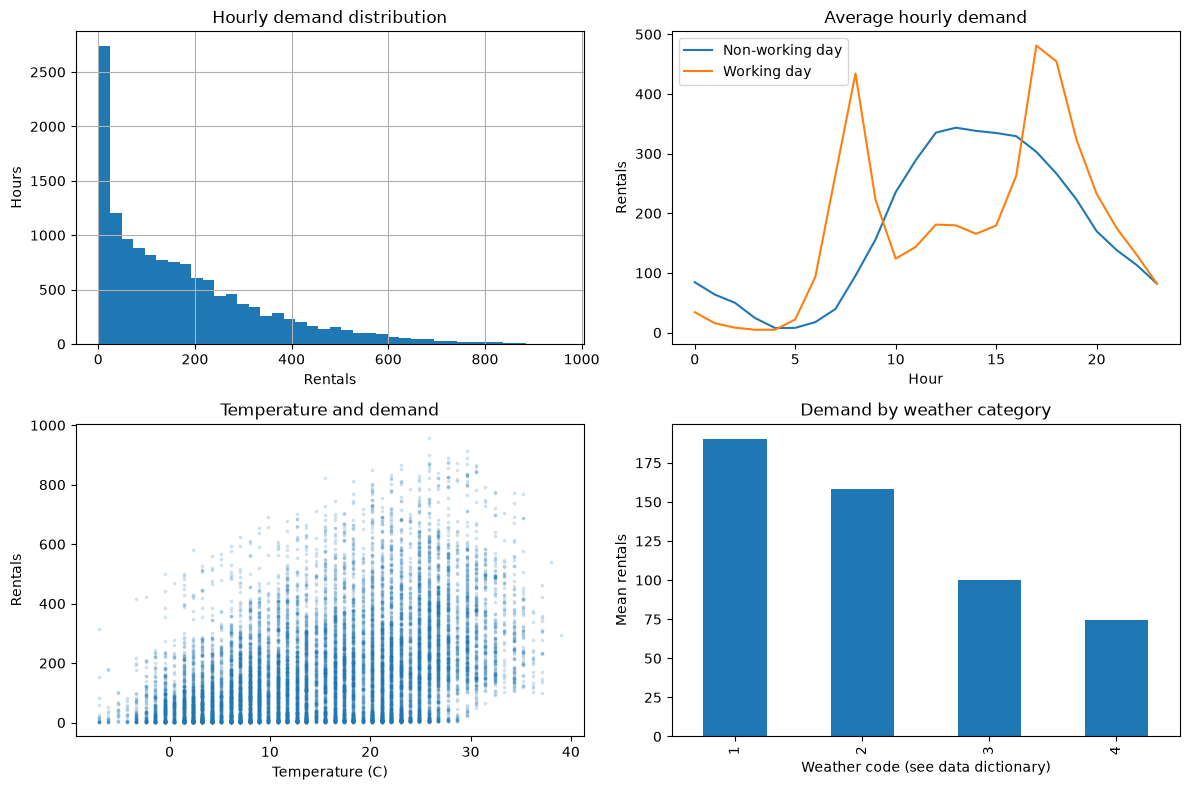

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
dev['cnt'].hist(bins=40, ax=axes[0,0]); axes[0,0].set(title='Hourly demand distribution', xlabel='Rentals', ylabel='Hours')
for group, frame in dev.groupby('workingday'):
    frame.groupby('hr')['cnt'].mean().plot(ax=axes[0,1], label='Working day' if group else 'Non-working day')
axes[0,1].set(title='Average hourly demand', xlabel='Hour', ylabel='Rentals'); axes[0,1].legend()
axes[1,0].scatter(dev['temp']*47-8, dev['cnt'], s=3, alpha=.15)
axes[1,0].set(title='Temperature and demand', xlabel='Temperature (C)', ylabel='Rentals')
dev.groupby('weathersit')['cnt'].mean().plot.bar(ax=axes[1,1])
axes[1,1].set(title='Demand by weather category', xlabel='Weather code (see data dictionary)', ylabel='Mean rentals')
fig.tight_layout(); fig.savefig(ART/'eda.png', dpi=150); plt.show()
# TEAM TASK: write one observation per chart; association does not prove causation.



## Pipeline and five time-ordered validation folds


In [5]:
preprocessor = ColumnTransformer([
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                       ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical),
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                       ('scale', StandardScaler())]), numeric)
])
def pipeline(model):
    return Pipeline([('prepare', clone(preprocessor)), ('model', model)])
# Expanding training windows, five validation folds, 24 observed-hour gap.
# Every fold trains only on observations earlier than its validation period.
cv = TimeSeriesSplit(n_splits=5, gap=24)
models = {
    'Dummy median': DummyRegressor(strategy='median'),
    'Ridge': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=100, min_samples_leaf=3, random_state=SEED, n_jobs=1),
    'Gradient Boosting': HistGradientBoostingRegressor(max_iter=150, early_stopping=False, random_state=SEED)
}
rows = []
for name, model in models.items():
    losses = -cross_val_score(pipeline(model), X, y, cv=cv, scoring='neg_mean_absolute_error', n_jobs=1)
    rows.append({'model': name, 'cv_mae': losses.mean(), 'cv_mae_std': losses.std(), 'fold_mae': losses.tolist()})
comparison = pd.DataFrame(rows).sort_values('cv_mae')
print(comparison.to_string(index=False))
comparison.to_csv(ART/'cv_comparison.csv', index=False)



/Users/bhmyatkyaw/Documents/Codex/2026-11-11/files-mentioned-by-the-user-ict336/work/venv/lib/python3.14/site-packages/joblib/externals/loky/backend/context.py:134: UserWarning: Could not find the number of physical cores for the following reason:
invalid literal for int() with base 10: ''
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "/Users/bhmyatkyaw/Documents/Codex/2026-11-11/files-mentioned-by-the-user-ict336/work/venv/lib/python3.14/site-packages/joblib/externals/loky/backend/context.py", line 264, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
  File "/Users/bhmyatkyaw/Documents/Codex/2026-11-11/files-mentioned-by-the-user-ict336/work/venv/lib/python3.14/site-packages/joblib/externals/loky/backend/context.py", line 420, in _count_physical_cores_darwin
    return int(cpu_info)


            model     cv_mae  cv_mae_std                                                   fold_mae
Gradient Boosting  73.430406   22.708524     [89.09684, 42.826573, 48.722893, 93.124937, 93.380788]
    Random Forest  74.080755   18.426251    [93.846791, 51.003399, 52.677783, 84.104685, 88.771119]
            Ridge  86.460524   19.870926  [88.233485, 66.838629, 61.531963, 102.863486, 112.835058]
     Dummy median 144.186263   36.420706 [145.789201, 128.306263, 92.36933, 149.770626, 204.695896]


## Tune the strongest candidate using development CV only


In [6]:
winner = comparison.loc[comparison.model != 'Dummy median'].iloc[0]['model']
grids = {
    'Ridge': {'model__alpha': [0.1, 1, 10, 100]},
    'Random Forest': {'model__min_samples_leaf': [1, 3, 6], 'model__max_features': [0.7, 1.0]},
    'Gradient Boosting': {'model__learning_rate': [0.05, 0.1], 'model__max_leaf_nodes': [15, 31], 'model__l2_regularization': [0, 1]}
}
search = GridSearchCV(pipeline(models[winner]), grids[winner], scoring='neg_mean_absolute_error', cv=cv, n_jobs=1)
search.fit(X, y)
print('Selected candidate:', winner, 'Tuned CV MAE:', -search.best_score_, 'Parameters:', search.best_params_)
summary = {'status':'development_only', 'selected_model':winner, 'cv_mae':float(-search.best_score_),
           'best_params':search.best_params_, 'test_cutoff':str(cutoff), 'seed':SEED,
           'features':features, 'success_relative_mae_reduction':SUCCESS_REDUCTION}
(ART/'development_info.json').write_text(json.dumps(summary, indent=2))



Selected candidate: Gradient Boosting Tuned CV MAE: 73.34102260056221 Parameters: {'model__l2_regularization': 1, 'model__learning_rate': 0.1, 'model__max_leaf_nodes': 15}


448

## Final test, interpretation, group check, and export: unlock once


In [7]:
if not FINAL_EVALUATION:
    print('Final test remains locked. No deployment model or test results exported.')
elif (ART/'model_info.json').exists():
    print('Preserving the original final evaluation; no test re-evaluation performed.')
    print((ART/'model_info.json').read_text())
else:
    best = search.best_estimator_  # Already refit on all development data, never on test.
    baseline = pipeline(models['Dummy median']).fit(X, y)
    Xt, yt = test[features], test['cnt']
    pred = best.predict(Xt)
    dummy_pred = baseline.predict(Xt)
    mae = mean_absolute_error(yt, pred)
    baseline_mae = mean_absolute_error(yt, dummy_pred)
    reduction = 1 - mae / baseline_mae
    scores = {'mae':float(mae), 'rmse':float(np.sqrt(mean_squared_error(yt,pred))),
              'r2':float(r2_score(yt,pred)), 'baseline_mae':float(baseline_mae),
              'relative_mae_reduction':float(reduction), 'success_met':bool(reduction >= SUCCESS_REDUCTION)}
    errors = test[['timestamp','workingday','weathersit','hr','cnt']].copy()
    errors['prediction'] = pred
    errors['absolute_error'] = np.abs(yt.to_numpy()-pred)
    errors.to_csv(ART/'test_errors.csv', index=False)
    groups = errors.groupby('workingday')['absolute_error'].agg(['size','mean'])
    groups.to_csv(ART/'group_errors.csv')
    group_gap = float(groups['mean'].max()-groups['mean'].min())
    # Operational group performance check, not evidence of demographic fairness.
    # Interpretation uses test data only after selection; do not tune from it.
    importance = permutation_importance(best, Xt, yt, scoring='neg_mean_absolute_error', n_repeats=5, random_state=SEED)
    pd.DataFrame({'feature':features,'mae_increase':importance.importances_mean,
                  'std':importance.importances_std}).sort_values('mae_increase',ascending=False).to_csv(ART/'feature_importance.csv',index=False)
    versions = {name:importlib.metadata.version(name) for name in ['numpy','pandas','scikit-learn','joblib','streamlit','matplotlib']}
    info = {**summary, 'status':'final', 'test_scores':scores, 'group_mae_gap':group_gap,
            'versions':versions, 'training_end':str(dev.timestamp.max()),
            'test_start':str(test.timestamp.min()), 'test_end':str(test.timestamp.max()),
            'source':'https://doi.org/10.24432/C5W894', 'licence':'CC BY 4.0'}
    joblib.dump(best, ART/'pipeline.joblib')
    (ART/'model_info.json').write_text(json.dumps(info, indent=2))
    (ROOT/'requirements.txt').write_text(''.join(f'{name}=={version}\n' for name,version in versions.items()))
    print(json.dumps(scores, indent=2)); print('Group MAE gap:', group_gap); print(groups)


{
  "mae": 91.92039387171512,
  "rmse": 130.2941037029629,
  "r2": 0.6508107309961979,
  "baseline_mae": 182.83572247706422,
  "relative_mae_reduction": 0.4972514526900177,
  "success_met": true
}
Group MAE gap: 6.311580206985468
            size       mean
workingday                 
0           1127  87.648134
1           2361  93.959715
